# 01 · FI-2010: com'è fatto un book L2

**FI-2010** (Ntakaris et al., 2018) è un dataset pubblico di dieci giorni di book a 10 livelli per cinque titoli della borsa finlandese. Per una introduzione ai limit order book si vedano Gould et al. (2013) e Bouchaud, Bonart, Donier e Gould (2018).

Caratteristiche che limitano l'uso di FI-2010 in questa tesi:

* contiene **snapshot normalizzati**, non prezzi in euro: il P&L calcolato è un **indicatore comparativo**, non un profitto monetario;
* è un dato **L2**: non si conoscono i singoli ordini né la posizione in coda;
* ogni file giornaliero **concatena cinque titoli anonimi**;
* registra **un'osservazione ogni dieci eventi** del book.

I termini tecnici sono spiegati nel **glossario** in fondo al notebook 06.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
from market_making_tesi import storage
from market_making_tesi.parsers import load_fi2010_matrix, fi2010_stock_segments
quality = R.load(ROOT, "quality").query("dataset == 'fi2010'")
INTERIM = R.data_available(ROOT, "data", "interim", "fi2010")
counts = quality.pivot(index="session", columns="symbol", values="records")
checks = pd.DataFrame({
    "titoli individuati": quality.groupby("session").symbol.nunique(),
    "osservazioni": quality.groupby("session").records.sum(),
    "book incrociati o spread non positivo": quality.groupby("session").crossed.sum(),
    "volumi non positivi": quality.groupby("session").nonpositive_size.sum(),
    "prezzi non finiti": quality.groupby("session").nonfinite_mid.sum(),
})
R.show_box("In breve", [
    f"{it(counts.values.sum())} osservazioni in {counts.size} titolo-giorni (10 giornate × 5 titoli).",
    f"Book incrociati, volumi non positivi o prezzi non finiti: {int(checks.iloc[:, 2:].sum().sum())}.",
    "Il midpoint resta invariato tra due osservazioni nella maggior parte dei casi (sezione 2).",
])
display(Markdown("**Controlli per giornata**"))
display(checks)

> **In breve**
>
> - 394.337 osservazioni in 50 titolo-giorni (10 giornate × 5 titoli).
> - Book incrociati, volumi non positivi o prezzi non finiti: 0.
> - Il midpoint resta invariato tra due osservazioni nella maggior parte dei casi (sezione 2).

**Controlli per giornata**

,titoli individuati,osservazioni,book incrociati o spread non positivo,volumi non positivi,prezzi non finiti
session,,,,,
day01,5,39512,0,0,0.0
day02,5,38397,0,0,0.0
day03,5,28535,0,0,0.0
day04,5,37023,0,0,0.0
day05,5,34785,0,0,0.0
day06,5,39152,0,0,0.0
day07,5,37346,0,0,0.0
day08,5,55478,0,0,0.0
day09,5,52172,0,0,0.0


## 1. Separare i cinque titoli

Nel file non c'è una colonna che indichi il titolo. Il passaggio da un titolo al successivo produce però un salto del midpoint molto più grande di qualsiasi movimento intraday: i confini si individuano dove il midpoint cambia di oltre il 5%. È una **procedura euristica**; si verifica che trovi esattamente cinque segmenti ogni giorno e che dentro ciascun segmento non restino salti anomali.

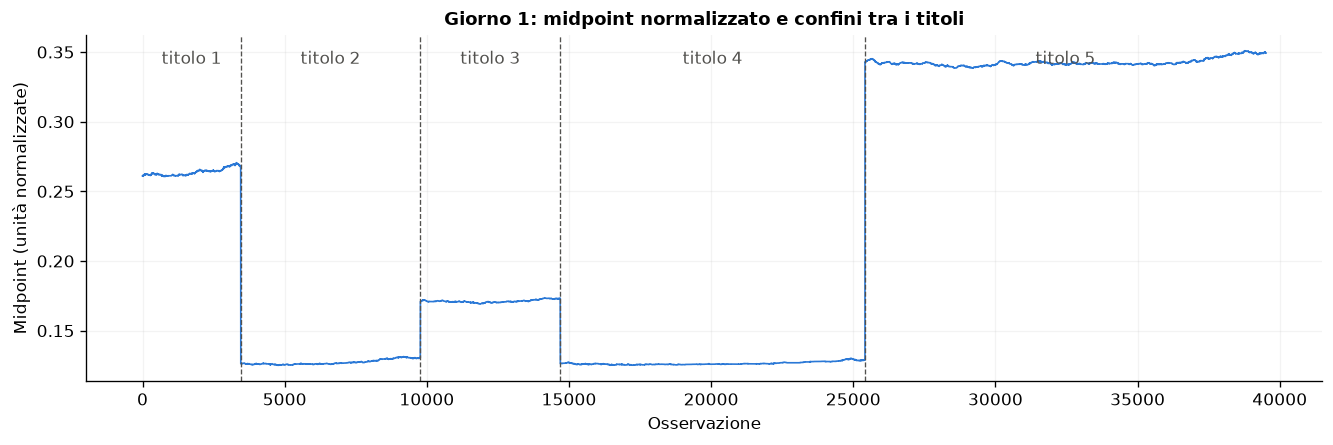

*Figura.* Midpoint del giorno 1 con i confini individuati (linee tratteggiate). I cinque titoli hanno livelli di prezzo diversi; dentro i segmenti il salto relativo massimo è 0,59%, molto sotto la soglia del 5%. *Limite:* la separazione è euristica: due titoli con prezzi normalizzati simili non sarebbero distinguibili.

In [2]:
if INTERIM:
    matrix = load_fi2010_matrix(ROOT / "data/raw/fi2010/fi2010_day01.txt")
    mid = (matrix[0] + matrix[2]) / 2
    bounds = fi2010_stock_segments(matrix)
    fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
    ax.plot(mid, color=R.COLORS["touch"], linewidth=1)
    for start, _ in bounds[1:]:
        ax.axvline(start, color=R.INK, linewidth=0.8, linestyle="--")
    for k, (start, stop) in enumerate(bounds, 1):
        ax.text((start + stop) / 2, mid.max(), f"titolo {k}", ha="center", va="top", color=R.INK)
    ax.set(title="Giorno 1: midpoint normalizzato e confini tra i titoli", xlabel="Osservazione", ylabel="Midpoint (unità normalizzate)")
    fig.savefig(FIGURES / "fi2010_confini.png", dpi=180, bbox_inches="tight")
    plt.show()
    jumps = []
    for session, symbol, path in storage.sessions(ROOT / "data/interim", "fi2010", "snapshots"):
        t = pd.read_parquet(path, columns=["bid_px_1", "ask_px_1"])
        m = (t.bid_px_1 + t.ask_px_1) / 2
        jumps.append((m.pct_change().abs().max()))
    R.caption("Midpoint del giorno 1 con i confini individuati (linee tratteggiate).",
              f"I cinque titoli hanno livelli di prezzo diversi; dentro i segmenti il salto relativo massimo è {pct(max(jumps), 2)}, "
              "molto sotto la soglia del 5%.",
              "la separazione è euristica: due titoli con prezzi normalizzati simili non sarebbero distinguibili.")
else:
    R.show_saved_figure(ROOT, "fi2010_confini.png", "Dati intermedi FI-2010 assenti.")

## 2. Spread e prezzo fermo

Lo **spread** in *tick* (il passo minimo di prezzo) è il guadagno massimo di una coppia di quote; la quota di osservazioni con **midpoint invariato** indica quanto spesso il mercato resta fermo.

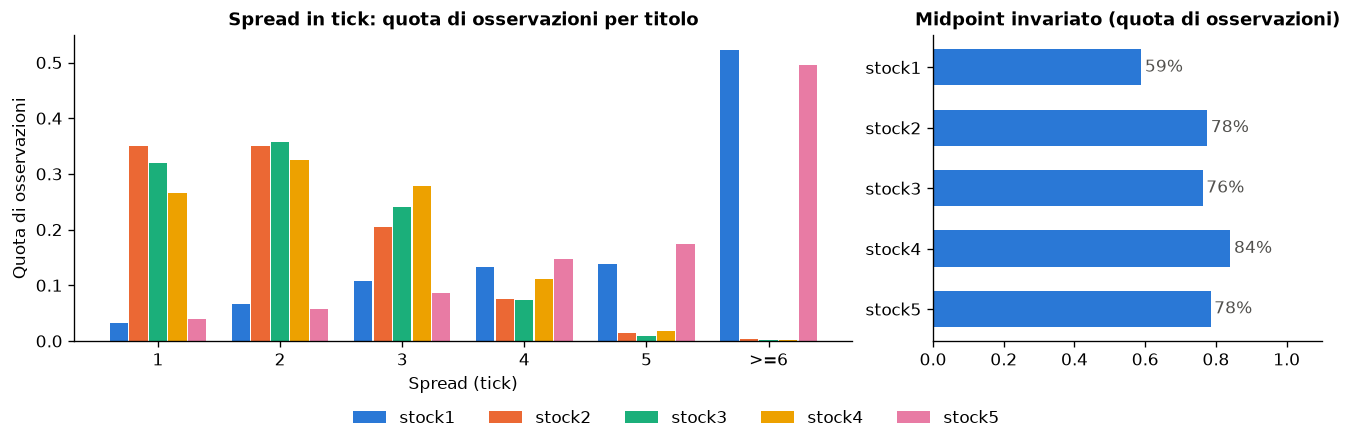

*Figura.* A sinistra la distribuzione dello spread in tick, a destra la quota di osservazioni con midpoint invariato. Il midpoint resta fermo nel 78% dei casi: la regola `touch` (notebook 02) considera eseguita una quota proprio quando il prezzo non si muove. *Limite:* con un'osservazione ogni dieci eventi non si vede che cosa accade tra due osservazioni.

In [3]:
if INTERIM:
    rows = []
    for session, symbol, path in storage.sessions(ROOT / "data/interim", "fi2010", "snapshots"):
        t = pd.read_parquet(path, columns=["bid_px_1", "ask_px_1"])
        rows.append(pd.DataFrame({"symbol": symbol, "session": session, "spread": t.ask_px_1 - t.bid_px_1,
                                  "ret": ((t.bid_px_1 + t.ask_px_1) / 2).diff()}))
    eda = pd.concat(rows)
    TICK = 0.0001
    eda["ticks"] = (eda.spread / TICK).round().clip(upper=6).astype(int)
    shares = eda.groupby("symbol").ticks.value_counts(normalize=True).unstack(fill_value=0)
    shares.columns = [f"{c}" if c < 6 else ">=6" for c in shares.columns]
    still = eda.groupby("symbol").ret.apply(lambda r: (r.dropna() == 0).mean())
    STOCK_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained", gridspec_kw={"width_ratios": [2, 1]})
    x = np.arange(len(shares.columns))
    for i, (symbol, row) in enumerate(shares.iterrows()):
        axes[0].bar(x + (i - 2) * 0.16, row.values, 0.15, color=STOCK_COLORS[i], label=symbol)
    axes[0].set_xticks(x, shares.columns)
    axes[0].set(title="Spread in tick: quota di osservazioni per titolo", xlabel="Spread (tick)", ylabel="Quota di osservazioni")
    fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=5, frameon=False)
    axes[1].barh(still.index[::-1], still.values[::-1], color=R.COLORS["touch"], height=0.6)
    for y, v in enumerate(still.values[::-1]):
        axes[1].text(v + 0.01, y, pct(v, 0), va="center", color=R.INK)
    axes[1].set(title="Midpoint invariato (quota di osservazioni)", xlim=(0, 1.1))
    for ax in axes:
        ax.grid(False)
    fig.savefig(FIGURES / "fi2010_distribuzioni.png", dpi=180, bbox_inches="tight")
    plt.show()
    R.caption("A sinistra la distribuzione dello spread in tick, a destra la quota di osservazioni con midpoint invariato.",
              f"Il midpoint resta fermo {R.nel((eda.ret == 0).mean(), 0)} dei casi: la regola `touch` (notebook 02) "
              "considera eseguita una quota proprio quando il prezzo non si muove.",
              "con un'osservazione ogni dieci eventi non si vede che cosa accade tra due osservazioni.")
else:
    R.show_saved_figure(ROOT, "fi2010_distribuzioni.png", "Dati intermedi FI-2010 assenti.")

## 3. Volatilità: distribuzione e finestra

La strategia opera solo quando la volatilità (deviazione standard delle variazioni del midpoint nelle ultime *W* osservazioni) è sotto una soglia stimata sul giorno 1. Una **finestra corta** (W = 20) reagisce subito ma accende e spegne la strategia di continuo; una **lunga** (W = 100) è stabile ma lenta. La tabella riassume la distribuzione della volatilità su tutte le osservazioni; il grafico mostra una sessione di test con la soglia del 75° percentile.

**Distribuzione della volatilità per finestra** (tutte le osservazioni, unità normalizzate)

,W = 20,W = 100
10° percentile,0.00e+00,1.87e-05
25° percentile,1.83e-05,2.65e-05
50° percentile,3.02e-05,3.49e-05
75° percentile,4.56e-05,4.82e-05
90° percentile,6.97e-05,6.79e-05


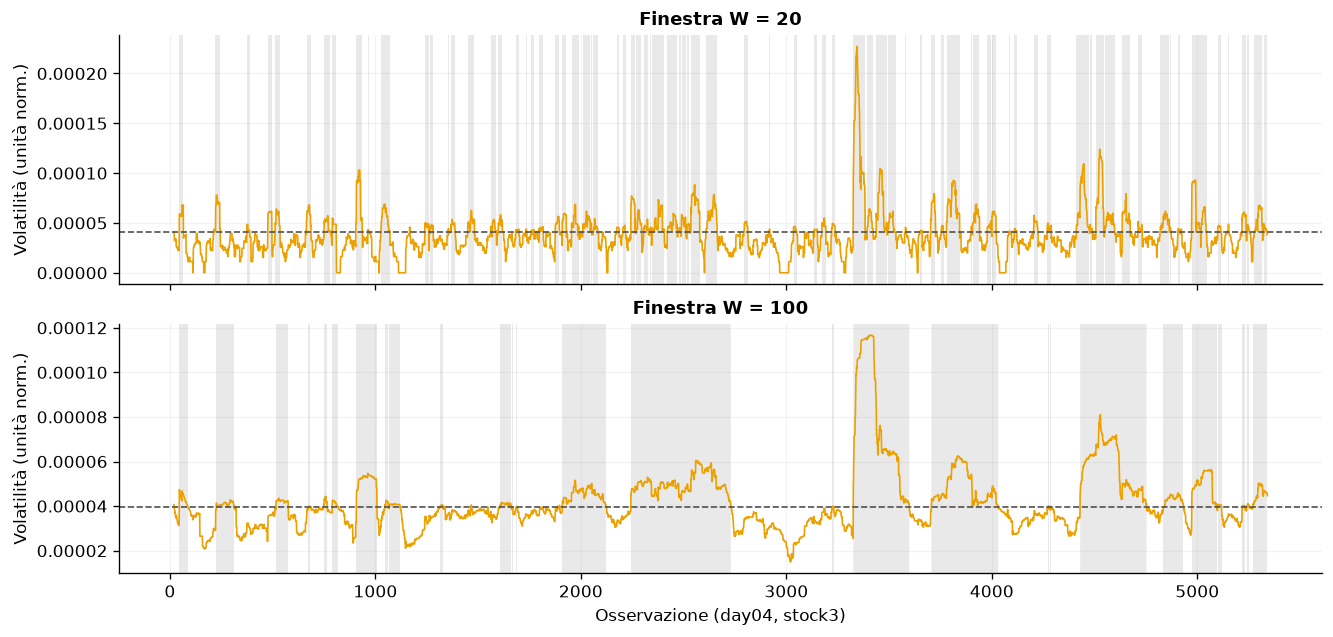

*Figura.* Volatilità stimata con due finestre, soglia del 75° percentile (tratteggio) e periodi di sospensione (grigio). La strategia sarebbe attiva nel 63% delle osservazioni con W = 20 e nel 53% con W = 100; con la finestra corta le sospensioni sono più frequenti e più brevi. *Limite:* la scelta tra finestre non si fa a occhio ma in validazione (notebook 02).

In [4]:
cal = R.load(ROOT, "calibration").query("dataset == 'fi2010' and session == 'day01'").set_index("symbol")
if INTERIM:
    dist = {}
    for w in (20, 100):
        vols = pd.concat([eda[eda.session.eq(s) & eda.symbol.eq(sym)].ret.rolling(w, min_periods=min(20, w)).std()
                          for (s, sym), _ in eda.groupby(["session", "symbol"])]).dropna()
        dist[f"W = {w}"] = vols.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).rename(lambda q: f"{int(q * 100)}° percentile")
    display(Markdown("**Distribuzione della volatilità per finestra** (tutte le osservazioni, unità normalizzate)"))
    display(pd.DataFrame(dist).style.format("{:.2e}"))
    session, symbol = "day04", "stock3"
    ret = eda[(eda.session == session) & (eda.symbol == symbol)].ret.reset_index(drop=True)
    fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, layout="constrained")
    active = {}
    for ax, w in zip(axes, (20, 100)):
        vol = ret.rolling(w, min_periods=min(20, w)).std()
        thr = cal.loc[symbol, f"threshold_w{w}_q75"]
        ax.plot(vol.index, vol, color=R.COLORS["queue"], linewidth=1)
        ax.axhline(thr, color=R.INK, linestyle="--", linewidth=1)
        ax.fill_between(vol.index, 0, 1, where=(vol > thr).to_numpy(), transform=ax.get_xaxis_transform(),
                        color=R.INK, alpha=0.12, linewidth=0, step="post")
        active[w] = (vol.dropna() <= thr).mean()
        ax.set(ylabel="Volatilità (unità norm.)", title=f"Finestra W = {w}")
    axes[1].set(xlabel=f"Osservazione ({session}, {symbol})")
    fig.savefig(FIGURES / "fi2010_volatilita_finestre.png", dpi=180, bbox_inches="tight")
    plt.show()
    R.caption("Volatilità stimata con due finestre, soglia del 75° percentile (tratteggio) e periodi di sospensione (grigio).",
              f"La strategia sarebbe attiva {R.nel(active[20], 0)} delle osservazioni con W = 20 e {R.nel(active[100], 0)} con W = 100; "
              "con la finestra corta le sospensioni sono più frequenti e più brevi.",
              "la scelta tra finestre non si fa a occhio ma in validazione (notebook 02).")
else:
    R.show_saved_figure(ROOT, "fi2010_volatilita_finestre.png", "Dati intermedi FI-2010 assenti.")